In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Import our custom modules
import data_loader
import features
import models
import prioritization

DATA_DIR = "/mnt/d/Mohamed Kanouni/MSc data science/machine learning/machine learning project/the_project/data/raw"


# 1. Load Data 
df_raw, stations_df = data_loader.load_and_prepare_data(DATA_DIR)

# 2. Engineer Features & Sample Stations
df_model = features.engineer_features(df_raw, n_stations=300)

# 3. Time Split & Create Labels
train_df, val_df, test_df = features.time_based_split(df_model)

# 4. Check Split
print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

Loading hourly panel...
Loading station information...
Data loaded. Missing capacity: 2.97%
Sampling 300 stations for memory optimization...
Train: 1,340,693 | Val: 367,141 | Test: 653,335


In [2]:
final_features = [
    'capacity', 'lon', 'dist_from_center_km', 
    'hour_of_day', 'day_of_week', 'month', 
    'hour_sin', 'hour_cos', 'is_weekend_x_hour', 
    'departures_lag_1h', 'arrivals_lag_1h', 
    'departures_roll_mean_3h', 'departures_roll_mean_24h'
]

model_reg = models.train_task1_regression(
    train_df, val_df, test_df, 
    features=final_features, 
    target='target_departures_2h'
)

Training Task 1 Regression Model...


/home/mohamed/citibike_venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.049743 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1211
[LightGBM] [Info] Number of data points in the train set: 1340693, number of used features: 13
[LightGBM] [Info] Start training from score 3.577793
Task 1 MAE: 1.8484 | RMSE: 3.1065


In [3]:
# Add net flow to features for classification
clf_features = final_features + ['net_flow_2h']

model_clf, preds_proba = models.train_task2_classification(
    train_df, val_df, test_df,
    features=clf_features,
    target='target_high_risk_2h'
)

Training Task 2 Classification Model...


/home/mohamed/citibike_venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 104105, number of negative: 1236588
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013529 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1373
[LightGBM] [Info] Number of data points in the train set: 1340693, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000


--- 🏆 TOP 10 STATIONS ---


,station_id,name,priority_score
0,6331.01,W 31 St & 7 Ave,0.804849
1,5905.12,Broadway & E 14 St,0.792382
2,6182.02,W 20 St & 7 Ave,0.782672
3,5880.02,W 4 St & 7 Ave S,0.758551
4,5779.11,Ave A & E 14 St,0.730089
5,5659.05,E 10 St & Ave A,0.627003
6,4565.07,Schermerhorn St & Court St,0.603457
7,5414.06,Allen St & Rivington St,0.589811
8,5303.06,Clinton St & Grand St,0.587656
9,6953.08,E 74 St & 1 Ave,0.567346


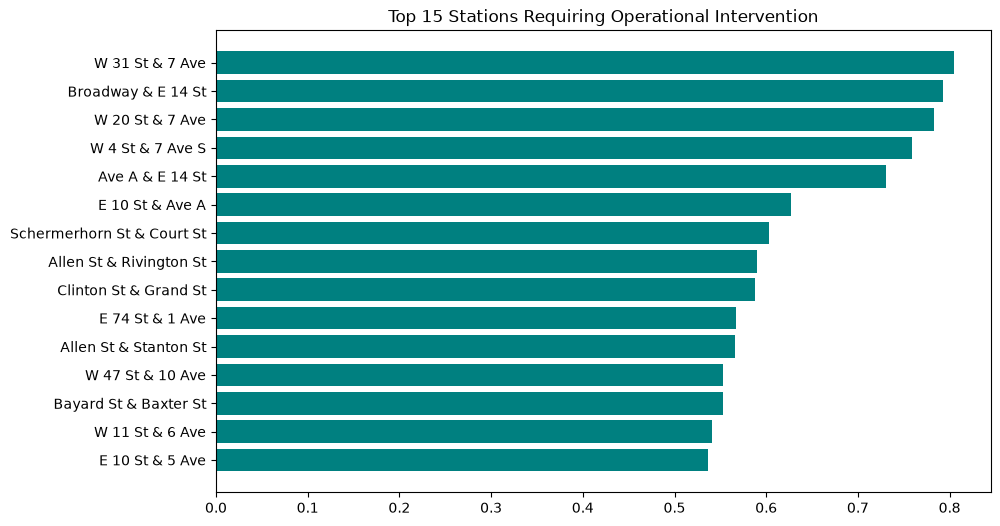

In [4]:
# We use the optimal threshold 0.7 found earlier
ranked_stations = prioritization.calculate_priorities(
    test_df, preds_proba, stations_df, threshold=0.7
)

print("--- 🏆 TOP 10 STATIONS ---")
display(ranked_stations[['station_id', 'name', 'priority_score']].head(10))

# Plot
top_15 = ranked_stations.head(15)
plt.figure(figsize=(10, 6))
plt.barh(top_15['name'], top_15['priority_score'], color='teal')
plt.gca().invert_yaxis()
plt.title('Top 15 Stations Requiring Operational Intervention')
plt.show()